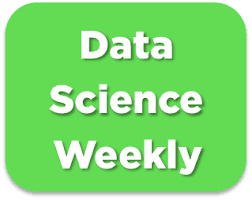

# Import libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.metrics import r2_score
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import cross_val_score

import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings(
    "ignore", category=DeprecationWarning
)  # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from IPython.display import display

# Read file with labels

In [2]:
df = pd.read_csv("walmart_sales.csv")

# Preprocessing

## preprocessing pandas

In [3]:
df.columns = df.columns.str.lower()
print(df.columns)

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')


### Missing values

In [4]:
print('Missing values treatment...')
# before = df.nunique()
cols = ['weekly_sales']
df = df.dropna(subset=cols) # drop lines where target values is missing. 

Missing values treatment...


### Convert data

In [5]:
categories = ['store', 'holiday_flag']

df[categories] = df[categories].astype('Int64') # convert categories in integers, avoid error "Cannot convert non-finite values".

In [6]:
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)
print(df[categories + ['date']].dtypes)

store           Int64
holiday_flag    Int64
date              str
dtype: object


### drop unused columns

In [7]:
df = df.drop(['date'], axis=1)
df.head(1)

,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86


### mask outlyers

In [8]:
mean = df['unemployment'].mean()
sigma = df['unemployment'].std()

mask = df['unemployment'].between(mean - 3 * sigma, mean + 3 * sigma)
df = df[mask]
print(df.shape)

(117, 7)


In [9]:
### drop store 11
count = df['store'].value_counts()
count[count < 2]
df = df.drop(df[df['store'] < 2].index)
print(df[df['store'] < 2]) 
df.head(1)

Empty DataFrame
Columns: [store, weekly_sales, holiday_flag, temperature, fuel_price, cpi, unemployment]
Index: []


,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86


# Baseline model

## preprocessing en sklearn

### Multivariate linear regression

#### Separate target variable Y from features X

In [10]:
# Separate target variable Y from features X

print("Separating labels from features...")
target = 'weekly_sales'

y = df.loc[:, target]# or df.iloc[:, -1] # or  df.loc[:, df.columns == target]
X = df.drop(target, axis=1) # or df.iloc[:, 0:-1]  # All columns are kept, except the target
# or df.loc[:, df.columns != target]
print("...Done.")

print("y : ")
print(y.head())
print()
print("X : ")
print(X.head())

Separating labels from features...
...Done.
y : 
0    1572117.54
1    1807545.43
3    1244390.03
4    1644470.66
5    1857533.70
Name: weekly_sales, dtype: float64

X : 
   store  holiday_flag  temperature  fuel_price     cpi  unemployment
0      6          <NA>        59.61        3.04  214.78          6.86
1     13             0        42.38        3.44  128.62          7.47
3     11             0        84.57         NaN  214.56          7.35
4      6             0        78.89        2.76  212.41          7.09
5      4             0          NaN        2.76  126.16          7.90


In [11]:
'''# Automatically detect names of numeric/categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Found numeric features ", numeric_features)
print("Found categorical features ", categorical_features)'''

'# Automatically detect names of numeric/categorical columns\nnumeric_features = X.select_dtypes(include="number").columns.tolist()\ncategorical_features = X.select_dtypes(exclude="number").columns.tolist()\n\nprint("Found numeric features ", numeric_features)\nprint("Found categorical features ", categorical_features)'

In [12]:
numeric_features = ['temperature', 'fuel_price', 'cpi', 'unemployment']
categorical_features = ['store', 'holiday_flag']

Remember to treat year, 'month', 'day', 'weekday' as numeric features (cf instructions)

#### Divide dataset train set & test set 

We apply different transformations to the features, depending on their types. Numeric columns will be standardized whereas categorical columns will be one-hot-encoded. As regards missing values imputation, it can apply to every column, but different rules may be used. 

In [13]:
# Divide dataset Train set & Test set
print("Dividing into train and test sets...")

bins = pd.qcut(y, q=4, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['store']
)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



We'll use simple imputer because we don't have any missing values. num_imputer = SimpleImputer(strategy="median")

We normalize numeric colomns to scale them down.

#### pipelines

In [14]:
print("Preprocessing X_train...")
print(X_train.head())
print()

# categoric

cat_transformer = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy="most_frequent")),
    ('catEncoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
])
# numerical

num_transformer = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler())
])

Preprocessing X_train...
     store  holiday_flag  temperature  fuel_price     cpi  unemployment
5        4             0          NaN        2.76  126.16          7.90
53      14          <NA>        41.76        3.62  184.99          8.55
33      14             1        37.00         NaN     NaN          8.42
27      16             0        43.95        3.83  192.83          6.34
107      8             1        33.34        2.55  214.62          6.30



In [15]:
#### pipeline global
print("Encoding categorical features and standardizing numerical features...")

preprocessor = ColumnTransformer(transformers=[
    ('cat_transformer', cat_transformer, categorical_features),
    ('num_transformer', num_transformer, numeric_features)
])

# Preprocessings on train set
print("Preprocessing sur le train set...")
X_train = preprocessor.fit_transform(X_train)
print('...Terminé.')
X_train[0:5] # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()


Encoding categorical features and standardizing numerical features...
Preprocessing sur le train set...
...Terminé.



Nous n'utilisons pas labelEncoder sur y_test car les labels sont déjà convertis sur converted

#### Test pipeline

In [16]:
# Preprocessings sur le test set
print("Preprocessing on test set...")
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
X_test[:5, :] # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore

Preprocessing on test set...
...Done.


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 25 stored elements and shape (5, 23)>

#### Train model

In [17]:

from sklearn.linear_model import LinearRegression

print("Train model...")
baseline = LinearRegression() # 
baseline.fit(X_train, y_train)
print("...Done.")

Train model...
...Done.


#### Performance evaluation

## Cross validation

In [18]:
# Perform 10-fold cross-validation
print("5-fold cross-validation...")
scores = cross_val_score(baseline, X_train, y_train, cv=(5))
print('The cross-validated R2 score is : ', scores.mean())
print('The standard deviation is : ', scores.std())

5-fold cross-validation...
The cross-validated R2 score is :  0.8931117048860446
The standard deviation is :  0.04166028892837336


#### Predictions

In [19]:
# Predictions on training set
print("Predictions on training set...")
y_train_pred = baseline.predict(X_train)
print("...Done.")
print(y_train_pred)
print()

Predictions on training set...
...Done.
[2121592.81866905 2029604.50262704 2079681.77210818  459048.01262795
  959670.50048288 1398328.12445642  347874.02397707 1944064.6233509
 1883269.63404925  426242.57007544 1090900.77619815 2027826.53453955
 1935434.96034765 2188476.00200516 1888218.43145446 1486915.26933848
  854235.38069055  465022.6505484  1970687.45857233  228711.33481925
 1955853.67989429 1852807.50025672  261229.84628861 2172958.4312559
 2048673.78795746 2202368.63049877  474995.27033507 1345781.87172613
  418208.27848248  496886.68492437  543709.91548846 1428477.09197244
  644712.1577761  1030624.64807452 1642544.76869854 2001898.4789385
 1055429.58480866 1793372.37928874 1976356.33678682  485397.51031598
 1961246.79257669 1987414.6031385  1025315.59655923 2094030.64366905
 1541242.74782896  228253.74605629  832046.47812205 1718293.82451436
  813164.54822026  892596.07079203 1382483.66233346  391626.48936422
 1684305.64415069  495115.3881242   516659.93856622  327609.694397

In [20]:
# Predictions on test set
print("Predictions on test set...")
y_test_pred = baseline.predict(X_test)
print("...Done.")
print(y_test_pred)
print()

Predictions on test set...
...Done.
[1405519.89124735  403738.40619449 2038143.59829527  778946.30664159
  348673.29126901  504634.66566579 1909934.39059114 1577700.03115625
 1186217.65976586  410045.41152559 2188723.58522355 2156608.94675604
  689390.82176504 1091832.17124311  488291.75491477  773947.10216022
 2004653.21894571  467993.10631196 1554231.28738374 1313581.37170098
 1989901.77531845 2060770.65219167]



In [21]:
# Print R^2 scores
print("R2 score on training set : ", r2_score(y_train, y_train_pred))
print("R2 score on test set : ", r2_score(y_test, y_test_pred))

R2 score on training set :  0.9633684068825312
R2 score on test set :  0.9541203833239376


The baseline model overfits.

Interpreting the models coefficients

In [22]:
baseline.coef_

array([  607569.43713914,  -994632.76918373,  1064897.88175089,
       -1122443.32430429,   148137.08832965,  -710723.67992636,
        -618408.00166949, -1002449.61749331,   929025.02289275,
         246152.88648731,   920665.76718907,   870882.11167296,
        -281525.87170396,  -877319.85787246,  -313740.11909254,
         152133.10050886,   374856.75253011,   606923.19274542,
         -10829.17440204,   -28446.77577736,   -52304.83927252,
         144588.62696173,   -81329.71424515])

In [23]:
column_names = []
for name, pipeline, features_list in preprocessor.transformers_: # loop over pipelines
    if name == 'num_transformer': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    else: # if pipeline is for categorical variables
        features = pipeline.named_steps['catEncoder'].get_feature_names_out() # get output columns names from OneHotEncoder
    column_names.extend(features) # concatenate features names

print("Names of columns corresponding to each coefficient: ", column_names)

Names of columns corresponding to each coefficient:  ['x0_2.0', 'x0_3.0', 'x0_4.0', 'x0_5.0', 'x0_6.0', 'x0_7.0', 'x0_8.0', 'x0_9.0', 'x0_10.0', 'x0_11.0', 'x0_13.0', 'x0_14.0', 'x0_15.0', 'x0_16.0', 'x0_17.0', 'x0_18.0', 'x0_19.0', 'x0_20.0', 'x1_1.0', 'temperature', 'fuel_price', 'cpi', 'unemployment']


In [24]:
# Create a pandas DataFrame
coefs = pd.DataFrame(index = column_names, data = baseline.coef_.transpose(), columns=["coefficients"])
coefs

,coefficients
x0_2.0,6.075694e+05
x0_3.0,-9.946328e+05
x0_4.0,1.064898e+06
x0_5.0,-1.122443e+06
x0_6.0,1.481371e+05
x0_7.0,-7.107237e+05
x0_8.0,-6.184080e+05
x0_9.0,-1.002450e+06
x0_10.0,9.290250e+05
x0_11.0,2.461529e+05


In [25]:
# Compute abs() and sort values
feature_importance = abs(coefs).sort_values(by = 'coefficients')
feature_importance

,coefficients
x1_1.0,1.082917e+04
temperature,2.844678e+04
fuel_price,5.230484e+04
unemployment,8.132971e+04
cpi,1.445886e+05
x0_6.0,1.481371e+05
x0_18.0,1.521331e+05
x0_11.0,2.461529e+05
x0_15.0,2.815259e+05
x0_17.0,3.137401e+05


In [26]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False,
                  margin = {'l': 120} # to avoid cropping of column names
                 )
fig.show()

In [27]:
'''import matplotlib.pyplot as plt

plt.scatter(y_test, y_test_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

'import matplotlib.pyplot as plt\n\nplt.scatter(y_test, y_test_pred)\nplt.xlabel("Valeurs réelles")\nplt.ylabel("Valeurs prédites")\nplt.show()'

In [28]:
'''plt.scatter(y_test, y_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

'plt.scatter(y_test, y_test_pred)\nplt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")\nplt.xlabel("Valeurs réelles")\nplt.ylabel("Valeurs prédites")\nplt.show()'

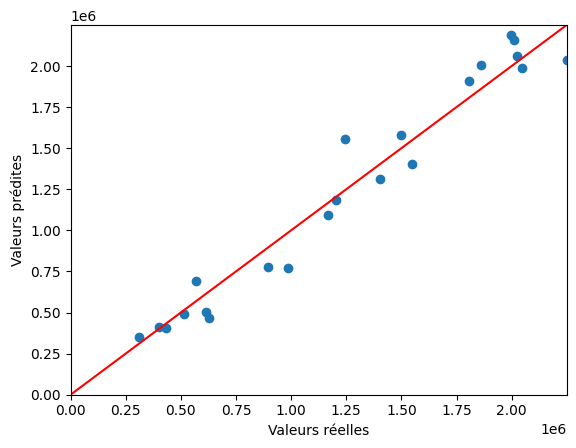

In [29]:
lim_max = max(y_test.max(), y_test_pred.max())

plt.scatter(y_test, y_test_pred)
plt.plot([0, lim_max], [0, lim_max], color="red")
plt.xlim(0, lim_max)
plt.ylim(0, lim_max)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()

In [30]:
'''plt.scatter(y_test, y_test_pred)
plt.xlim(0)
plt.ylim(0)
plt.show()'''

'plt.scatter(y_test, y_test_pred)\nplt.xlim(0)\nplt.ylim(0)\nplt.show()'